# Exploración de datos
---

**Autor:** Jaime Lozano Cillero

# 0. Preparación del entorno

In [1]:
from dotenv import load_dotenv
import time
import getpass
import os
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from openai import OpenAI

load_dotenv()

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

GENERATION_MODEL = os.getenv("OPENAI_GENERATION_MODEL", "gpt-4.1-mini")
EMBEDDING_MODEL = os.getenv("OPENAI_EMBEDDING_MODEL", "text-embedding-3-small")

client = OpenAI()

RAG_K = 5

PDF_PATH = Path("../../data/raw/TENERIFE.pdf")

print("Modelo generativo:", GENERATION_MODEL)
print("Modelo de embeddings:", EMBEDDING_MODEL)
print("PDF:", PDF_PATH.resolve())

Modelo generativo: gpt-4.1-mini
Modelo de embeddings: text-embedding-3-small
PDF: C:\Users\Jaime\Documents\Pontia\modulo-06-llms\entrega-final\pontia-llms-entrega-final\data\raw\TENERIFE.pdf


In [2]:
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings

llm = init_chat_model(
    GENERATION_MODEL,
    model_provider="openai",
    temperature=0.1,
    max_tokens=1000,
)
embeddings = OpenAIEmbeddings(model=EMBEDDING_MODEL)

# 1. Carga de datos

Se usará el fichero PDF local: `data/raw/TENERIFE.pdf`.

El objetivo es que el contenido acabe convertido en objetos `Document`, que tienen dos partes:

- `page_content`: el texto del documento.
- `metadata`: información adicional, como fuente, página, ruta, fecha, categoría, etc.

In [3]:
from pypdf import PdfReader
from langchain_core.documents import Document

if not PDF_PATH.exists():
    raise FileNotFoundError(f"No se encontró el PDF en {PDF_PATH.resolve()}")

reader = PdfReader(str(PDF_PATH))

docs = [
    Document(
        page_content=page.extract_text().strip(),
        metadata={
            "source": str(PDF_PATH),
            "page": page_number,
            "total_pages": len(reader.pages),
        },
    )
    for page_number, page in enumerate(reader.pages, start=1)
]

print("Número de páginas cargadas:", len(docs))
print("Metadata de la primera página:", docs[0].metadata)
print("Primeros caracteres:\n")
print(docs[0].page_content[:512])

Número de páginas cargadas: 25
Metadata de la primera página: {'source': '..\\..\\data\\raw\\TENERIFE.pdf', 'page': 1, 'total_pages': 25}
Primeros caracteres:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler -


In [4]:
print(docs[7].page_content)

o Playa de Benijo [vídeo - ubicación] 
Playa de arena negra, si el día está despejado, de los atardeceres más 
espectaculares que podéis ver en la isla. 
Para llegar a esta playa, aparcar por aquí y, para acceder a la playa, se accede 
desde aquí (puede ser que os encontréis con el acceso cortado con una valla, 
pero da igual, podéis acceder igualmente). 
• La Orotava 
Este es el pueblo más bonito y maravilloso del mundo (no es porque yo sea de allí).


In [5]:
print(reader.metadata)
print(reader.page_layout)
print(reader.page_mode)

{'/Title': 'Microsoft Word - TENERIFE.docx', '/Creator': 'Microsoft Word', '/CreationDate': "D:20250713200001+00'00'", '/ModDate': "D:20250713200001+00'00'"}
None
None


# 2. Chunking

## 2.1 Estrategia 1

### 2.1.1 Chunking

In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=80,
    add_start_index=True,
)

splits = text_splitter.split_documents(docs)

# Añadimos un identificador simple a cada chunk para poder citarlo luego.
for i, doc in enumerate(splits):
    doc.metadata["chunk_id"] = i
    doc.metadata["source_name"] = PDF_PATH.name

print("Número de chunks:", len(splits))
print("\nEjemplo de chunk:\n")
print(splits[0].page_content)
print("\nMetadata:", splits[0].metadata)

Número de chunks: 47

Ejemplo de chunk:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo

Metadata: {'source': '..\\..\\data\\raw\\TENERIFE.pdf', 'page': 1, 'total_pages': 25, 'start_index': 0, 'chunk_id': 0, 'source_name': 'TENERIFE.pdf'}


### 2.1.1 Embeddings y vector store

El objetivo del RAG es recuperar información relacionada con las consultas variables del usuario. Para ello, necesitamos comparar el signficado de la pregunta con el significado de nuestros textos (chunks) para recuperar los que sean más parecidos. Esos chunks recuperados serán provistos al LLM como contexto de tal manera que lo integre en su respuesta al usuario y dé como resultado una respuesta relevante.

Para poder comparar significados, cada texto será transformado a embedding y se compararán usando una medida de similaridad.

Se usará la clase `InMemoryVectorStore` para la transformación y almacenamiento de los embeddings en memoria.

In [7]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)
document_ids = vector_store.add_documents(splits)

print("Documentos indexados:", len(document_ids))
print("Primeros IDs:", document_ids[:3])

Documentos indexados: 47
Primeros IDs: ['394538ca-0363-4b2b-9199-9aac6ba1ed8d', '95f91e37-ae84-4bce-951e-77d53b7d1672', '4deebc28-728f-44d1-a35b-38a30cbc33e2']


### 2.1.2 Recuperación 

Comprobar el mecanismo de recuperación para verificar que se recuperan chunks relevantes con la consulta del usuario.

In [8]:
def mostrar_documentos_recuperados(documentos):
    for i, doc in enumerate(documentos, start=1):
        print(f"Resultado {i}")
        print("Fuente:", doc.metadata.get("source_name"))
        print("Página:", doc.metadata.get("page"))
        print("Chunk:", doc.metadata.get("chunk_id"))
        print(doc.page_content)
        print("-" * 80)

pregunta = "¿Dònde puedo comer sushi en Tenerife?"
retrieved_docs = vector_store.similarity_search(pregunta, k=3)

mostrar_documentos_recuperados(retrieved_docs)

Resultado 1
Fuente: TENERIFE.pdf
Página: 25
Chunk: 45
▪ Arepera La Carajita (entre La Orotava y el Puerto de la Cruz 
[ubicación]. Este sitio tiene las mejores arepas que podréis comer en 
vuestra vida y son baratísimas. Recomendación: La Fogalera y Reina 
Pepiada. Y pedir de entrantes una degustación de cachapitas). 
Importante ir con hambre.  
▪ Atuvera (entre La Orotava y el Puerto de la Cruz [ubicación]). 
Recomendable reservar. 
▪ Restaurante Fujiyama (sushi en la zona de Santa Cruz [ubicación])
--------------------------------------------------------------------------------
Resultado 2
Fuente: TENERIFE.pdf
Página: 24
Chunk: 44
El Paraíso (espectacular la salsa de aguacate de aquí. 
Recomendación: menú feliz de bocadillo de pollo + Nestea de 
mango-piña) - Cafetería Zumería Mango - El Track 
 
 
Nota:   los bocadillos de pollo del norte de Tenerife no son como los bocadillos 
que se hacen en otros lugares de España.   Recomiendo que lo prueben, está 
increíble.
-------------------

### 2.1.3 Análisis de la recuperación RAG

Métricas clave:
- Hit Rate@k: Proporción de consultas donde al menos un fragmento relevante aparece en los $k$ documentos recuperados.

- MRR@k (Mean Reciprocal Rank): Penaliza si el documento relevante aparece en posiciones inferiores del ranking:$$\text{MRR} = \frac{1}{\vert{}Q\vert{}} \sum_{i=1}^{\vert{}Q\vert{}} \frac{1}{\text{rank}_i}$$

 k  Page Hit Rate    MRR  Keyword Coverage  Strict Hit Rate
 1           0.95 0.9500            0.7775             0.45
 2           0.95 0.9500            0.9125             0.80
 3           0.95 0.9500            0.9125             0.80
 4           1.00 0.9625            0.9250             0.80
 5           1.00 0.9625            0.9250             0.80
 6           1.00 0.9625            0.9250             0.80


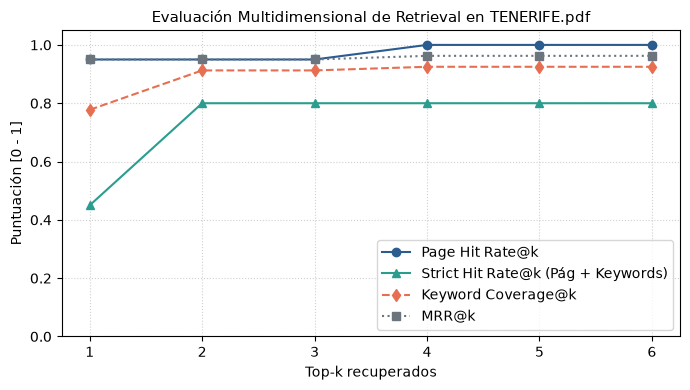

In [9]:
# 1. Dataset de prueba sobre TENERIFE.pdf
EVAL_DATASET = [
    # -----------------------------------------------------------------------
    # BLOQUE 1: ZONA METROPOLITANA Y LA LAGUNA
    # -----------------------------------------------------------------------
    {
        "query": "¿Cuál es la ruta a pie recomendada para visitar Santa Cruz de Tenerife y dónde se aconseja aparcar el coche?",
        "expected_page": 0,
        "category": "macro_itinerario",
        "keywords": ["parque marítimo", "avenida marítima", "plaza de españa"],
    },
    {
        "query": "¿Qué curiosidad histórica presenta el reloj del torreón de la Iglesia de la Concepción en La Laguna?",
        "expected_page": 2,
        "category": "micro_detalle",
        "keywords": ["iglesia de la concepción", "iiii", "números romanos"],
    },
    {
        "query": "¿Qué plato específico y qué restaurante recomienda para comer al callejear hacia la Plaza del Adelantado en La Laguna?",
        "expected_page": 3,
        "category": "micro_gastronomia",
        "keywords": ["la cueva de casiano", "batata", "almogrote"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 2: PARQUE RURAL DE ANAGA Y SUS COSTAS
    # -----------------------------------------------------------------------
    {
        "query": "¿Por qué destaca el Parque Rural de Anaga a nivel natural y cuál es el itinerario diario sugerido para recorrerlo?",
        "expected_page": 4,
        "category": "macro_naturaleza",
        "keywords": ["reserva de la biosfera", "endemismos", "playa de benijo", "mirador de la jardina"],
    },
    {
        "query": "¿En qué mirador de Anaga se puede tomar la foto típica en un pasillo superfrondoso de vegetación?",
        "expected_page": 5,
        "category": "micro_detalle",
        "keywords": ["pico del inglés", "pasillo", "frondoso"],
    },
    {
        "query": "¿Cómo se llega a la Playa de Benijo y qué indicación da sobre la valla que corta el acceso?",
        "expected_page": 7,
        "category": "micro_detalle",
        "keywords": ["playa de benijo", "arena negra", "valla", "atardeceres"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 3: VALLE DE LA OROTAVA Y SUS PLAYAS
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué récord Guinness ostenta La Orotava y qué singularidad geográfica comparte con el Teide?",
        "expected_page": 8,
        "category": "macro_patrimonio",
        "keywords": ["récord guinness", "alfombra", "desnivel", "3.718"],
    },
    {
        "query": "¿En qué punto de la Calle de la Carrera de La Orotava se puede comprar gofio tradicional?",
        "expected_page": 8,
        "category": "micro_detalle",
        "keywords": ["molino de chano", "gofio", "carrera"],
    },
    {
        "query": "¿Qué precauciones sobre las mareas y el mar se deben tener al bajar a las playas de Los Patos y El Ancón?",
        "expected_page": 9,
        "category": "micro_seguridad",
        "keywords": ["los patos", "ancón", "difícil acceso", "marea esté baja"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 4: PUERTO DE LA CRUZ E ISLA BAJA
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué recorrido a pie se sugiere en el Puerto de la Cruz desde la explanada del muelle hasta la Plaza del Charco?",
        "expected_page": 10,
        "category": "macro_itinerario",
        "keywords": ["explanada del muelle", "lago de martiánez", "calle quintana", "plaza del charco"],
    },
    {
        "query": "¿Qué localidades y carreteras componen la ruta típica de domingo por la comarca de la Isla Baja?",
        "expected_page": 11,
        "category": "macro_itinerario",
        "keywords": ["isla baja", "icod de los vinos", "garachico", "tf5", "tf42"],
    },
    {
        "query": "¿Junto a qué fortaleza están las Piscinas Naturales del Caletón en Garachico y qué pizzería se recomienda allí?",
        "expected_page": 11,
        "category": "micro_detalle",
        "keywords": ["castillo de san miguel", "caletón", "chuso", "rugantino"],
    },
    {
        "query": "¿Qué pastelería se recomienda visitar al aparcar cerca de la Plaza de los Remedios en Buenavista del Norte?",
        "expected_page": 12,
        "category": "micro_gastronomia",
        "keywords": ["buenavista", "plaza de los remedios", "el aderno", "dulcito"],
    },
    {
        "query": "¿Cómo se accede actualmente a la Punta de Teno y qué superproducción cinematográfica grabó allí su inicio?",
        "expected_page": 13,
        "category": "micro_curiosidad",
        "keywords": ["punta de teno", "línea 369", "titsa", "fast & furious 6"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 5: PARQUE NACIONAL DEL TEIDE
    # -----------------------------------------------------------------------
    {
        "query": "¿Cuál es la subida recomendada al Teide en coche y qué mirador destaca por las tonalidades de su roca y el mar de nubes?",
        "expected_page": 14,
        "category": "macro_paisaje",
        "keywords": ["tf24", "la esperanza", "la tarta", "mar de nubes"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 6: ZONA SUR (ADEJE, MASCA Y ENTRETENIMIENTO)
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué áreas diferenciadas tiene el Monkey Beach Club sobre la Playa de Troya y cuál es idónea para cócteles al atardecer?",
        "expected_page": 16,
        "category": "micro_ocio",
        "keywords": ["playa de troya", "monkey beach club", "bésamemucho", "kong", "cielo"],
    },
    {
        "query": "¿Qué récords mundiales ostenta el parque acuático Siam Park en Costa Adeje?",
        "expected_page": 20,
        "category": "macro_atraccion",
        "keywords": ["siam park", "ola artificial", "río lento", "tailandesa"],
    },
    {
        "query": "¿Desde qué municipio se accede al caserío de Masca y qué trámite previo se exige para hacer la bajada de su barranco?",
        "expected_page": 21,
        "category": "micro_logistica",
        "keywords": ["santiago del teide", "barranco de masca", "reservar", "antelación", "pateada"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 7: GASTRONOMÍA LOCAL AUTÉNTICA (GUACHINCHES Y BOCADILLOS)
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué particularidades hacen genuino al Guachinche El Cubano en Santa Úrsula y qué únicas tres bebidas ofrecen?",
        "expected_page": 23,
        "category": "micro_gastronomia",
        "keywords": ["guachinche el cubano", "camino de tierra", "no hay carta", "vino", "seven up", "agua"],
    },
    {
        "query": "¿Qué arepas y entrante recomienda pedir en la Arepera La Carajita situada entre La Orotava y Puerto de la Cruz?",
        "expected_page": 24,
        "category": "micro_gastronomia",
        "keywords": ["la carajita", "la fogalera", "reina pepiada", "cachapitas"],
    },
]


def evaluate_retrieval(vector_store, dataset: list[dict], k_values=(1, 2, 3, 4, 5, 6)):
    """Calcula Hit Rate@k y MRR@k para diferentes profundidades de búsqueda."""
    results = {k: {"hits": 0, "reciprocal_ranks": []} for k in k_values}

    for item in dataset:
        for k in k_values:
            retrieved = vector_store.similarity_search(item["query"], k=k)
            retrieved_pages = [doc.metadata.get("page") for doc in retrieved]

            # Verificación de acierto
            expected = item["expected_page"]
            if expected in retrieved_pages:
                results[k]["hits"] += 1
                rank = retrieved_pages.index(expected) + 1
                results[k]["reciprocal_ranks"].append(1.0 / rank)
            else:
                results[k]["reciprocal_ranks"].append(0.0)

    total = len(dataset)
    metrics_summary = []
    for k in k_values:
        hit_rate = results[k]["hits"] / total
        mrr = sum(results[k]["reciprocal_ranks"]) / total
        metrics_summary.append({"k": k, "Hit Rate": hit_rate, "MRR": mrr})

    return pd.DataFrame(metrics_summary)

def evaluate_retrieval_with_keywords(
    vector_store,
    dataset: list[dict],
    k_values=(1, 2, 3, 4, 5, 6),
):
    """Evalúa la recuperación combinando acierto de página (metadato)

    y presencia de entidades/términos clave (contenido textual).
    """
    total = len(dataset)
    metrics_summary = []

    for k in k_values:
        page_hits = 0
        strict_hits = 0
        total_keyword_coverage = 0.0
        reciprocal_ranks = []

        for item in dataset:
            query = item["query"]
            expected_page = item["expected_page"]
            keywords = [kw.lower() for kw in item.get("keywords", [])]

            retrieved = vector_store.similarity_search(query, k=k)

            # 1. Extracción de metadatos y contenido
            retrieved_pages = [doc.metadata.get("page")-1 for doc in retrieved]
            all_content = " ".join(doc.page_content.lower() for doc in retrieved)

            # 2. Evaluación por página y MRR
            page_found = expected_page in retrieved_pages
            if page_found:
                page_hits += 1
                rank = retrieved_pages.index(expected_page) + 1
                reciprocal_ranks.append(1.0 / rank)
            else:
                reciprocal_ranks.append(0.0)

            # 3. Evaluación de keywords en el texto recuperado
            if keywords:
                found_keywords = sum(1 for kw in keywords if kw in all_content)
                coverage = found_keywords / len(keywords)
                total_keyword_coverage += coverage
                keywords_present = (coverage == 1.0)
            else:
                total_keyword_coverage += 1.0
                keywords_present = True

            # 4. Strict Hit: misma página Y todas las keywords presentes
            if page_found and keywords_present:
                strict_hits += 1

        metrics_summary.append(
            {
                "k": k,
                "Page Hit Rate": page_hits / total,
                "MRR": sum(reciprocal_ranks) / total,
                "Keyword Coverage": total_keyword_coverage / total,
                "Strict Hit Rate": strict_hits / total,
            }
        )

    return pd.DataFrame(metrics_summary)

# Ejecución y visualización
# df_metrics = evaluate_retrieval(vector_store, EVAL_DATASET)
# print(df_metrics)

df_metrics = evaluate_retrieval_with_keywords(vector_store, EVAL_DATASET)
print(df_metrics.to_string(index=False))

# Gráfico para el notebook
# fig, ax = plt.subplots(figsize=(6, 3.5))
# ax.plot(df_metrics["k"], df_metrics["Hit Rate"], marker="o", label="Hit Rate@k", color="#2b5c8f")
# ax.plot(df_metrics["k"], df_metrics["MRR"], marker="s", linestyle="--", label="MRR@k", color="#e26d5c")
# ax.set_title("Rendimiento del Retrieval en TENERIFE.pdf", fontsize=11)
# ax.set_xlabel("Top-k recuperados")
# ax.set_ylabel("Puntuación")
# ax.set_ylim(0, 1.05)
# ax.grid(True, linestyle=":", alpha=0.6)
# ax.legend()
# plt.tight_layout()
# plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_metrics["k"], df_metrics["Page Hit Rate"], marker="o", label="Page Hit Rate@k", color="#2b5c8f")
ax.plot(df_metrics["k"], df_metrics["Strict Hit Rate"], marker="^", label="Strict Hit Rate@k (Pág + Keywords)", color="#2a9d8f")
ax.plot(df_metrics["k"], df_metrics["Keyword Coverage"], marker="d", linestyle="--", label="Keyword Coverage@k", color="#e76f51")
ax.plot(df_metrics["k"], df_metrics["MRR"], marker="s", linestyle=":", label="MRR@k", color="#6c757d")

ax.set_title("Evaluación Multidimensional de Retrieval en TENERIFE.pdf", fontsize=11)
ax.set_xlabel("Top-k recuperados")
ax.set_ylabel("Puntuación [0 - 1]")
ax.set_ylim(0, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
primer_caso = EVAL_DATASET[0]
doc_top1 = vector_store.similarity_search(primer_caso["query"], k=1)[0]

print("Esperado por EVAL_DATASET :", primer_caso["expected_page"])
print("Guardado en el Vector Store:", doc_top1.metadata.get("page"))
print("Tipo de dato de la página   :", type(doc_top1.metadata.get("page")))

Esperado por EVAL_DATASET : 0
Guardado en el Vector Store: 1
Tipo de dato de la página   : <class 'int'>


## 2.2 Estrategia 2

## 2.2.1 Chunking

In [11]:
# text_splitter = RecursiveCharacterTextSplitter(
#     chunk_size=1000,
#     chunk_overlap=200,
#     add_start_index=True,
# )

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    add_start_index=True,
    separators=[
        "\n\n",
        "\n• ",
        "\n▪ ",
        "\n- ",
        "\n o ",
        "\n",
        ". ",
        " ",
    ],
)

splits = text_splitter.split_documents(docs)

# Añadimos un identificador simple a cada chunk para poder citarlo luego.
for i, doc in enumerate(splits):
    doc.metadata["chunk_id"] = i
    doc.metadata["source_name"] = PDF_PATH.name

print("Número de chunks:", len(splits))
print("\nEjemplo de chunk:\n")
print(splits[0].page_content)
print("\nMetadata:", splits[0].metadata)

Número de chunks: 33

Ejemplo de chunk:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler - ubicación –; ir hacia el Parque García Sanabria - 
ubicación -; y bajar de nuevo hacia Plaza de España pasando por la Plaza del 
Príncipe - ubicación). 
- Volver de nuevo a por el coche. 
- Ir hacia la playa de Las Teresitas (ubicación). 
Los puntos de interés sugeridos son estos: 
o Parque Marítimo César Manrique [vídeo - ubicación] 
Conjunto de piscinas naturales.

Metadata: {'source': '..\\..\\data\\raw\\TENERIFE.pdf', 'page': 1, 'total_pa

### 2.2.1 Embeddings y vector store

El objetivo del RAG es recuperar información relacionada con las consultas variables del usuario. Para ello, necesitamos comparar el signficado de la pregunta con el significado de nuestros textos (chunks) para recuperar los que sean más parecidos. Esos chunks recuperados serán provistos al LLM como contexto de tal manera que lo integre en su respuesta al usuario y dé como resultado una respuesta relevante.

Para poder comparar significados, cada texto será transformado a embedding y se compararán usando una medida de similaridad.

Se usará la clase `InMemoryVectorStore` para la transformación y almacenamiento de los embeddings en memoria.

In [12]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)
document_ids = vector_store.add_documents(splits)

print("Documentos indexados:", len(document_ids))
print("Primeros IDs:", document_ids[:3])

Documentos indexados: 33
Primeros IDs: ['e3468d77-e2bd-4117-b50c-f8a64416b351', '6efc3f5f-d0cf-4670-8e00-1427eb93c95d', '693502ab-0bd9-4422-a6f7-de53027a4603']


### 2.2.2 Recuperación 

Comprobar el mecanismo de recuperación para verificar que se recuperan chunks relevantes con la consulta del usuario.

In [13]:
def mostrar_documentos_recuperados(documentos):
    for i, doc in enumerate(documentos, start=1):
        print(f"Resultado {i}")
        print("Fuente:", doc.metadata.get("source_name"))
        print("Página:", doc.metadata.get("page"))
        print("Chunk:", doc.metadata.get("chunk_id"))
        print(doc.page_content)
        print("-" * 80)

pregunta = "¿Dònde puedo comer sushi en Tenerife?"
retrieved_docs = vector_store.similarity_search(pregunta, k=3)

mostrar_documentos_recuperados(retrieved_docs)

Resultado 1
Fuente: TENERIFE.pdf
Página: 24
Chunk: 31
▪ Pizzería Gioconda (zona de La Orotava [ubicación]) [Tripadvisor] 
▪ El Palestra (zona de La Orotava [ubicación]. Este es el típico sitio que 
ha estado toda la vida en La Orotava y que te pides a domicilio cuando 
tienes el antojo. Nosotros solo pedimos una cosa: Plato feliz de pizza + 
Nestea de mango-piña para beber. [Tripadvisor] 
▪ Sitios de bocadillos top: Cafetería Deyfe - Bar-Cafetería Australia - Bar 
El Paraíso (espectacular la salsa de aguacate de aquí. 
Recomendación: menú feliz de bocadillo de pollo + Nestea de 
mango-piña) - Cafetería Zumería Mango - El Track 
 
 
Nota:   los bocadillos de pollo del norte de Tenerife no son como los bocadillos 
que se hacen en otros lugares de España.   Recomiendo que lo prueben, está 
increíble.
--------------------------------------------------------------------------------
Resultado 2
Fuente: TENERIFE.pdf
Página: 25
Chunk: 32
▪ Arepera La Carajita (entre La Orotava y el Puerto de l

### 2.1.3 Análisis de la recuperación RAG

Métricas clave:

- Page Hit Rate@k: Proporción de consultas donde al menos un fragmento recuperado pertenece a la página esperada.

- MRR@k (Mean Reciprocal Rank): Mide la efectividad del recuperador para colocar el primer fragmento de información relevante en una posición alta de la lista de resultados.

- Keyword Coverage@k: Proporción de keywords esperadas presentes dentro del texto de los chunks recuperados.

- Strict Hit Rate@k: exige que el fragmento pertenezca a la página esperada y además contenga las entidades clave (keywords) necesarias para responder.


Páginas cargadas: 25 | Primera página (Base 1): 1

Iniciando simulación comparativa de Chunking con InMemoryVectorStore...

✓ Pequeño (500 / 80)        -> 51 chunks en 23.45s
✓ Medio-Bajo (700 / 120)    -> 40 chunks en 25.18s
✓ Medio (900 / 180)         -> 35 chunks en 23.80s
✓ Grande (1200 / 250)       -> 29 chunks en 23.39s

 COMPARATIVA MATRICIAL POR MÉTRICA Y PROFUNDIDAD (k)

▶ PAGE HIT RATE @ k:
k                                   1       2       3       4       5       6
Configuración Chunking Chunks                                                
Pequeño (500 / 80)     51      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Medio-Bajo (700 / 120) 40      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Medio (900 / 180)      35      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Grande (1200 / 250)    29      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
------------------------------------------------------------------------------

▶ STRICT HIT RATE @ k (Página + Keywords):
k    

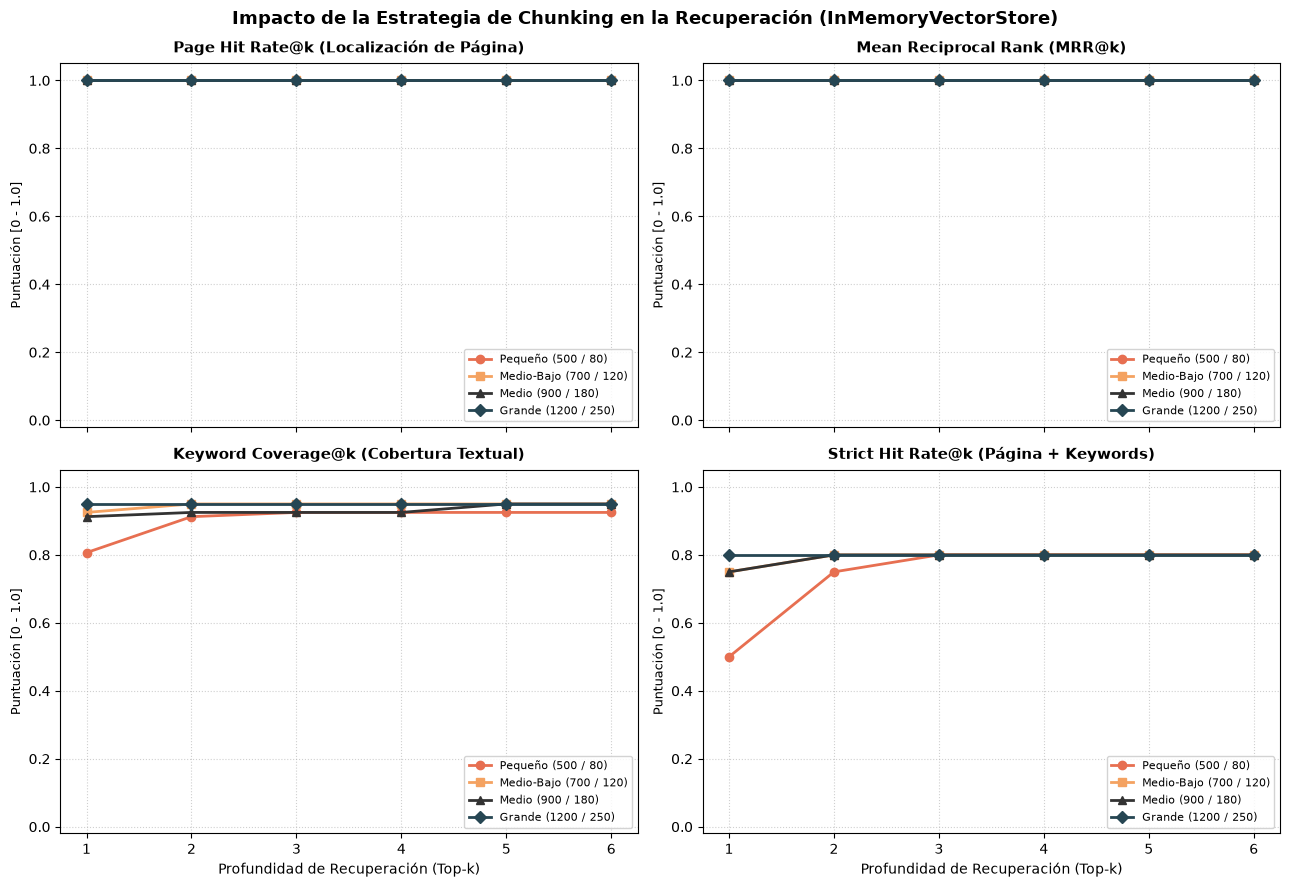

In [ ]:
# ---------------------------------------------------------------------------
# 1. Carga del PDF
# ---------------------------------------------------------------------------
PDF_PATH = Path("../../data/raw/TENERIFE.pdf")

if not PDF_PATH.exists():
    raise FileNotFoundError(f"No se encontró el PDF en {PDF_PATH.resolve()}")

reader = PdfReader(str(PDF_PATH))

base_docs = [
    Document(
        page_content=page.extract_text().strip(),
        metadata={
            "source": PDF_PATH.name,
            "page": page_number,  # Base 1: 1 a 25
            "total_pages": len(reader.pages),
        },
    )
    for page_number, page in enumerate(reader.pages, start=1) # Base 1: 1 a 25
]

print(f"Páginas cargadas: {len(base_docs)} | Primera página (Base 1): {base_docs[0].metadata['page']}")

# ---------------------------------------------------------------------------
# 2. Separadores estructurales y Escenarios de Simulación
# ---------------------------------------------------------------------------
CUSTOM_SEPARATORS = [
    "\n\n",   # Secciones mayores
    "\n• ",   # Puntos de interés y municipios
    "\n▪ ",   # Sub-recomendaciones (restaurantes, locales)
    "\n- ",   # Pasos de rutas o itinerarios
    "\n o ",  # Listados secundarios
    "\n",     # Saltos de línea
    ". ",     # Frases
    " ",      # Palabras
]

SCENARIOS = [
    {"name": "Pequeño (500 / 80)", "chunk_size": 500, "chunk_overlap": 80},
    {"name": "Medio-Bajo (700 / 120)", "chunk_size": 700, "chunk_overlap": 120},
    {"name": "Medio (900 / 180)", "chunk_size": 900, "chunk_overlap": 180},
    {"name": "Grande (1200 / 250)", "chunk_size": 1200, "chunk_overlap": 250},
]

# ---------------------------------------------------------------------------
# 3. Conjunto de evaluación
# ---------------------------------------------------------------------------
EVAL_DATASET = [
    # -----------------------------------------------------------------------
    # BLOQUE 1: ZONA METROPOLITANA Y LA LAGUNA
    # -----------------------------------------------------------------------
    {
        "query": "¿Cuál es la ruta a pie recomendada para visitar Santa Cruz de Tenerife y dónde se aconseja aparcar el coche?",
        "expected_page": 1,
        "category": "macro_itinerario",
        "keywords": ["parque marítimo", "avenida marítima", "plaza de españa"],
    },
    {
        "query": "¿Qué curiosidad histórica presenta el reloj del torreón de la Iglesia de la Concepción en La Laguna?",
        "expected_page": 3,
        "category": "micro_detalle",
        "keywords": ["iglesia de la concepción", "iiii", "números romanos"],
    },
    {
        "query": "¿Qué plato específico y qué restaurante recomienda para comer al callejear hacia la Plaza del Adelantado en La Laguna?",
        "expected_page": 4,
        "category": "micro_gastronomia",
        "keywords": ["la cueva de casiano", "batata", "almogrote"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 2: PARQUE RURAL DE ANAGA Y SUS COSTAS
    # -----------------------------------------------------------------------
    {
        "query": "¿Por qué destaca el Parque Rural de Anaga a nivel natural y cuál es el itinerario diario sugerido para recorrerlo?",
        "expected_page": 5,
        "category": "macro_naturaleza",
        "keywords": ["reserva de la biosfera", "endemismos", "playa de benijo", "mirador de la jardina"],
    },
    {
        "query": "¿En qué mirador de Anaga se puede tomar la foto típica en un pasillo superfrondoso de vegetación?",
        "expected_page": 6,
        "category": "micro_detalle",
        "keywords": ["pico del inglés", "pasillo", "frondoso"],
    },
    {
        "query": "¿Cómo se llega a la Playa de Benijo y qué indicación da sobre la valla que corta el acceso?",
        "expected_page": 8,
        "category": "micro_detalle",
        "keywords": ["playa de benijo", "arena negra", "valla", "atardeceres"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 3: VALLE DE LA OROTAVA Y SUS PLAYAS
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué récord Guinness ostenta La Orotava y qué singularidad geográfica comparte con el Teide?",
        "expected_page": 9,
        "category": "macro_patrimonio",
        "keywords": ["récord guinness", "alfombra", "desnivel", "3.718"],
    },
    {
        "query": "¿En qué punto de la Calle de la Carrera de La Orotava se puede comprar gofio tradicional?",
        "expected_page": 9,
        "category": "micro_detalle",
        "keywords": ["molino de chano", "gofio", "carrera"],
    },
    {
        "query": "¿Qué precauciones sobre las mareas y el mar se deben tener al bajar a las playas de Los Patos y El Ancón?",
        "expected_page": 10,
        "category": "micro_seguridad",
        "keywords": ["los patos", "ancón", "difícil acceso", "marea esté baja"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 4: PUERTO DE LA CRUZ E ISLA BAJA
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué recorrido a pie se sugiere en el Puerto de la Cruz desde la explanada del muelle hasta la Plaza del Charco?",
        "expected_page": 11,
        "category": "macro_itinerario",
        "keywords": ["explanada del muelle", "lago de martiánez", "calle quintana", "plaza del charco"],
    },
    {
        "query": "¿Qué localidades y carreteras componen la ruta típica de domingo por la comarca de la Isla Baja?",
        "expected_page": 12,
        "category": "macro_itinerario",
        "keywords": ["isla baja", "icod de los vinos", "garachico", "tf5", "tf42"],
    },
    {
        "query": "¿Junto a qué fortaleza están las Piscinas Naturales del Caletón en Garachico y qué pizzería se recomienda allí?",
        "expected_page": 12,
        "category": "micro_detalle",
        "keywords": ["castillo de san miguel", "caletón", "chuso", "rugantino"],
    },
    {
        "query": "¿Qué pastelería se recomienda visitar al aparcar cerca de la Plaza de los Remedios en Buenavista del Norte?",
        "expected_page": 13,
        "category": "micro_gastronomia",
        "keywords": ["buenavista", "plaza de los remedios", "el aderno", "dulcito"],
    },
    {
        "query": "¿Cómo se accede actualmente a la Punta de Teno y qué superproducción cinematográfica grabó allí su inicio?",
        "expected_page": 14,
        "category": "micro_curiosidad",
        "keywords": ["punta de teno", "línea 369", "titsa", "fast & furious 6"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 5: PARQUE NACIONAL DEL TEIDE
    # -----------------------------------------------------------------------
    {
        "query": "¿Cuál es la subida recomendada al Teide en coche y qué mirador destaca por las tonalidades de su roca y el mar de nubes?",
        "expected_page": 15,
        "category": "macro_paisaje",
        "keywords": ["tf24", "la esperanza", "la tarta", "mar de nubes"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 6: ZONA SUR (ADEJE, MASCA Y ENTRETENIMIENTO)
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué áreas diferenciadas tiene el Monkey Beach Club sobre la Playa de Troya y cuál es idónea para cócteles al atardecer?",
        "expected_page": 17,
        "category": "micro_ocio",
        "keywords": ["playa de troya", "monkey beach club", "bésamemucho", "kong", "cielo"],
    },
    {
        "query": "¿Qué récords mundiales ostenta el parque acuático Siam Park en Costa Adeje?",
        "expected_page": 21,
        "category": "macro_atraccion",
        "keywords": ["siam park", "ola artificial", "río lento", "tailandesa"],
    },
    {
        "query": "¿Desde qué municipio se accede al caserío de Masca y qué trámite previo se exige para hacer la bajada de su barranco?",
        "expected_page": 22,
        "category": "micro_logistica",
        "keywords": ["santiago del teide", "barranco de masca", "reservar", "antelación", "pateada"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 7: GASTRONOMÍA LOCAL AUTÉNTICA (GUACHINCHES Y BOCADILLOS)
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué particularidades hacen genuino al Guachinche El Cubano en Santa Úrsula y qué únicas tres bebidas ofrecen?",
        "expected_page": 24,
        "category": "micro_gastronomia",
        "keywords": ["guachinche el cubano", "camino de tierra", "no hay carta", "vino", "seven up", "agua"],
    },
    {
        "query": "¿Qué arepas y entrante recomienda pedir en la Arepera La Carajita situada entre La Orotava y Puerto de la Cruz?",
        "expected_page": 25,
        "category": "micro_gastronomia",
        "keywords": ["la carajita", "la fogalera", "reina pepiada", "cachapitas"],
    },
]


# ---------------------------------------------------------------------------
# 4. Construcción del Vector Store con InMemoryVectorStore
# ---------------------------------------------------------------------------
def build_vector_store_for_scenario(
    docs: list[Document],
    chunk_size: int,
    chunk_overlap: int,
    embeddings: OpenAIEmbeddings,
) -> tuple[InMemoryVectorStore, int]:
    """Genera los chunks y crea una instancia limpia de InMemoryVectorStore."""
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=CUSTOM_SEPARATORS,
        add_start_index=True,
    )
    split_chunks = splitter.split_documents(docs)

    for idx, chunk in enumerate(split_chunks, start=1):
        chunk.metadata["chunk_id"] = idx

    # InMemoryVectorStore gestiona los vectores en memoria RAM efímera
    vector_store = InMemoryVectorStore.from_documents(split_chunks, embeddings)
    return vector_store, len(split_chunks)

# ---------------------------------------------------------------------------
# 5. Evaluación de Métricas de Recuperación
# ---------------------------------------------------------------------------
def evaluate_scenario_retrieval(
    vector_store: InMemoryVectorStore,
    dataset: list[dict],
    k_values: tuple[int, ...] = (1, 2, 3, 4, 5, 6),
) -> list[dict]:
    """Calcula Page Hit Rate, MRR, Keyword Coverage y Strict Hit Rate."""
    total_queries = len(dataset)
    metrics_summary = []

    for k in k_values:
        page_hits = 0
        strict_hits = 0
        total_keyword_coverage = 0.0
        reciprocal_ranks = []

        for item in dataset:
            query = item["query"]
            expected_page = int(item["expected_page"])
            keywords = [kw.lower() for kw in item.get("keywords", [])]

            retrieved = vector_store.similarity_search(query, k=k)

            retrieved_pages = [
                int(doc.metadata.get("page"))
                for doc in retrieved
                if doc.metadata.get("page") is not None
            ]
            all_content = " ".join(doc.page_content.lower() for doc in retrieved)

            # 1. Page Hit Rate y MRR
            if expected_page in retrieved_pages:
                page_hits += 1
                rank = retrieved_pages.index(expected_page) + 1
                reciprocal_ranks.append(1.0 / rank)
            else:
                reciprocal_ranks.append(0.0)

            # 2. Keyword Coverage
            if keywords:
                found_kws = sum(1 for kw in keywords if kw in all_content)
                coverage = found_kws / len(keywords)
                total_keyword_coverage += coverage
                all_kws_present = (coverage == 1.0)
            else:
                total_keyword_coverage += 1.0
                all_kws_present = True

            # 3. Strict Hit Rate
            if (expected_page in retrieved_pages) and all_kws_present:
                strict_hits += 1

        metrics_summary.append({
            "k": k,
            "Page Hit Rate": page_hits / total_queries,
            "MRR": sum(reciprocal_ranks) / total_queries,
            "Keyword Coverage": total_keyword_coverage / total_queries,
            "Strict Hit Rate": strict_hits / total_queries,
        })

    return metrics_summary




# ---------------------------------------------------------------------------
# 6. Ejecución del Experimento Multiescenario
# ---------------------------------------------------------------------------
all_results = []

print("\nIniciando simulación comparativa de Chunking con InMemoryVectorStore...\n")

for sc in SCENARIOS:
    t0 = time.perf_counter()
    name = sc["name"]
    c_size = sc["chunk_size"]
    c_overlap = sc["chunk_overlap"]

    vs, total_chunks = build_vector_store_for_scenario(
        docs=base_docs,
        chunk_size=c_size,
        chunk_overlap=c_overlap,
        embeddings=embeddings,
    )

    metrics = evaluate_scenario_retrieval(vs, EVAL_DATASET, k_values=(1, 2, 3, 4, 5, 6))
    elapsed = time.perf_counter() - t0

    print(f"✓ {name:25} -> {total_chunks:2} chunks en {elapsed:.2f}s")

    for row in metrics:
        row["Scenario"] = name
        row["chunk_size"] = c_size
        row["chunk_overlap"] = c_overlap
        row["total_chunks"] = total_chunks
        all_results.append(row)

df_experiments = pd.DataFrame(all_results)

# ---------------------------------------------------------------------------
# 7. Visualización de Tablas de Datos
# ---------------------------------------------------------------------------

def print_separator(title: str, width: int = 78):
    print("\n" + "=" * width)
    print(f" {title}")
    print("=" * width)


# A) TABLAS MATRICIALES COMPARATIVAS (Escenario vs k para cada métrica)
# ---------------------------------------------------------------------------
print_separator("COMPARATIVA MATRICIAL POR MÉTRICA Y PROFUNDIDAD (k)")

metrics_display = [
    ("Page Hit Rate", "PAGE HIT RATE @ k"),
    ("Strict Hit Rate", "STRICT HIT RATE @ k (Página + Keywords)"),
    ("MRR", "MEAN RECIPROCAL RANK (MRR @ k)"),
    ("Keyword Coverage", "KEYWORD COVERAGE @ k"),
]

for col_metric, metric_title in metrics_display:
    print(f"\n▶ {metric_title}:")
    
    # Creamos tabla pivote: Filas = Escenario (con chunks), Columnas = k
    pivot_table = df_experiments.pivot_table(
        index=["Scenario", "total_chunks"],
        columns="k",
        values=col_metric,
        sort=False,
    )
    
    # Renombramos el índice para mayor claridad en el print
    pivot_table.index.names = ["Configuración Chunking", "Chunks"]
    
    # Formateo a 4 decimales
    formatted_pivot = pivot_table.map(lambda v: f"{v:0.4f}")
    print(formatted_pivot.to_string())
    print("-" * 78)


# B) TABLA COMPLETA DESGLOSADA POR ESCENARIO
# ---------------------------------------------------------------------------
print_separator("DESGLOSE COMPLETO DE RESULTADOS POR ESCENARIO")

cols_to_show = [
    "k",
    "Page Hit Rate",
    "MRR",
    "Keyword Coverage",
    "Strict Hit Rate",
]

for scenario_name, group in df_experiments.groupby("Scenario", sort=False):
    chunks_count = group["total_chunks"].iloc[0]
    c_size = group["chunk_size"].iloc[0]
    c_overlap = group["chunk_overlap"].iloc[0]
    
    print(f"\n📦 ESCENARIO: {scenario_name}")
    print(f"   Parámetros: chunk_size={c_size} | chunk_overlap={c_overlap} | Total Chunks={chunks_count}")
    print("-" * 72)
    
    df_sub = group[cols_to_show].copy()
    # Formateo visual numérico
    df_sub["Page Hit Rate"] = df_sub["Page Hit Rate"].map(lambda v: f"{v:0.4f}")
    df_sub["MRR"] = df_sub["MRR"].map(lambda v: f"{v:0.4f}")
    df_sub["Keyword Coverage"] = df_sub["Keyword Coverage"].map(lambda v: f"{v:0.4f}")
    df_sub["Strict Hit Rate"] = df_sub["Strict Hit Rate"].map(lambda v: f"{v:0.4f}")
    
    print(df_sub.to_string(index=False))


# C) RESUMEN EJECUTIVO EN PORCENTAJE (Para memoria / informe en Markdown)
# ---------------------------------------------------------------------------
print_separator("TABLA RESUMEN EJECUTIVO (Puntos de corte k=1, k=2, k=4)")

df_k_eval = df_experiments[df_experiments["k"].isin([1, 2, 4])].copy()

# Preparamos una tabla horizontal clara
resumen = df_k_eval.pivot_table(
    index="Scenario",
    columns="k",
    values=["Page Hit Rate", "Strict Hit Rate", "Keyword Coverage", "MRR"],
    sort=False,
)

# Mostramos en porcentaje para lectura ágil
resumen_pct = resumen.map(lambda v: f"{v * 100:5.1f}%")
print(resumen_pct.to_string())

palette = {
    "Pequeño (500 / 80)": "#e76f51",
    "Medio-Bajo (700 / 120)": "#f4a261",
    "Recomendado (900 / 180)": "#2a9d8f",
    "Grande (1200 / 250)": "#264653",
}
markers = ["o", "s", "^", "D"]

metrics_to_plot = [
    ("Page Hit Rate", "Page Hit Rate@k (Localización de Página)"),
    ("MRR", "Mean Reciprocal Rank (MRR@k)"),
    ("Keyword Coverage", "Keyword Coverage@k (Cobertura Textual)"),
    ("Strict Hit Rate", "Strict Hit Rate@k (Página + Keywords)"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
axes = axes.flatten()

k_vals = sorted(df_experiments["k"].unique())

for idx, (col_name, title) in enumerate(metrics_to_plot):
    ax = axes[idx]
    
    for (scenario_name, df_sc), marker in zip(df_experiments.groupby("Scenario", sort=False), markers):
        color = palette.get(scenario_name, "#333333")
        ax.plot(
            df_sc["k"],
            df_sc[col_name],
            marker=marker,
            linewidth=2,
            markersize=6,
            label=scenario_name,
            color=color,
        )

    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.set_ylabel("Puntuación [0 - 1.0]", fontsize=9)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(k_vals)
    ax.grid(True, linestyle=":", alpha=0.6)
    
    if idx in (2, 3):
        ax.set_xlabel("Profundidad de Recuperación (Top-k)", fontsize=10)
    
    ax.legend(loc="lower right", fontsize=8, framealpha=0.85)

plt.suptitle(
    "Impacto de la Estrategia de Chunking en la Recuperación (InMemoryVectorStore)",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

# 5. Añadir los chunks al contexto del LLM

Se añaden los chunks recuperados al prompt que se envía al LLM.

Queremos que el modelo:

1. Responda usando solo el contexto.
2. Diga que no tiene información si el contexto no contiene la respuesta.
3. Cite las fuentes utilizadas.

In [15]:
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Eres un guía turístico con más de 20 años de experiencia en la isla Tenerife."
            "Responde en español utilizando expresiones típicas canarias y usando únicamente el contexto proporcionado."
            "Si el contexto no contiene la respuesta, di claramente: 'No tengo información suficiente en la base documental'. "
            "No inventes datos. Cita las fuentes usadas al final.",
        ),
        (
            "user",
            "Pregunta:\n{question}\n\nContexto recuperado:\n{context}\n\nRespuesta:",
        ),
    ]
)

In [16]:
def format_docs_with_sources(documentos):
    bloques = []
    for i, doc in enumerate(documentos, start=1):
        source = doc.metadata.get("source_name", "fuente desconocida")
        page = doc.metadata.get("page", "?")
        chunk_id = doc.metadata.get("chunk_id", "?")
        bloques.append(
            f"[Fuente {i}: {source}, página {page}, chunk {chunk_id}]\n{doc.page_content}"
        )
    return "\n\n".join(bloques)


def answer_with_rag(question: str, k: int = 3, show_context: bool = False):
    retrieved_docs = vector_store.similarity_search(question, k=k)
    context = format_docs_with_sources(retrieved_docs)

    if show_context:
        print("CONTEXTO RECUPERADO")
        print(context)
        print("=" * 80)

    messages = rag_prompt.invoke({"question": question, "context": context})
    answer = llm.invoke(messages)

    return {
        "question": question,
        "answer": answer.content,
        "context": retrieved_docs,
        "prompt": messages,
    }

In [17]:
result = answer_with_rag(
    pregunta,
    k=RAG_K,
    show_context=True,
)

print(result["answer"])

CONTEXTO RECUPERADO
[Fuente 1: TENERIFE.pdf, página 24, chunk 31]
▪ Pizzería Gioconda (zona de La Orotava [ubicación]) [Tripadvisor] 
▪ El Palestra (zona de La Orotava [ubicación]. Este es el típico sitio que 
ha estado toda la vida en La Orotava y que te pides a domicilio cuando 
tienes el antojo. Nosotros solo pedimos una cosa: Plato feliz de pizza + 
Nestea de mango-piña para beber. [Tripadvisor] 
▪ Sitios de bocadillos top: Cafetería Deyfe - Bar-Cafetería Australia - Bar 
El Paraíso (espectacular la salsa de aguacate de aquí. 
Recomendación: menú feliz de bocadillo de pollo + Nestea de 
mango-piña) - Cafetería Zumería Mango - El Track 
 
 
Nota:   los bocadillos de pollo del norte de Tenerife no son como los bocadillos 
que se hacen en otros lugares de España.   Recomiendo que lo prueben, está 
increíble.

[Fuente 2: TENERIFE.pdf, página 25, chunk 32]
▪ Arepera La Carajita (entre La Orotava y el Puerto de la Cruz 
[ubicación]. Este sitio tiene las mejores arepas que podréis comer e

Probamos a preguntar algo un poco difuso:

In [18]:
result = answer_with_rag(
    "Me gustaría bañarme en el mar",
    k=RAG_K,
    show_context=True,
)

print(result["answer"])

CONTEXTO RECUPERADO
[Fuente 1: TENERIFE.pdf, página 20, chunk 22]
o Playa del Camisón 
Esta es una playa pequeñita que a nosotros en concreto nos gusta mucho.

[Fuente 2: TENERIFE.pdf, página 11, chunk 10]
tendréis poca playa (especialmente a la del Ancón) y tened mucho respeto al mar en 
estas playas, que la corriente es muy traicionera.

[Fuente 3: TENERIFE.pdf, página 10, chunk 9]
o La Playa de Los Patos 
o Playa del Ancón 
 
Nota: Para llegar estas playas hay que caminar un rato y algunas son de difícil acceso 
(la de Los Patos). También hay que ir a estas playas cuando la marea esté baja, si no

[Fuente 4: TENERIFE.pdf, página 23, chunk 26]
• El Médano / La Tejita 
Playas tipiquísimas de Tenerife y otra de las estampas de la isla con Montaña Roja al 
fondo. Nota: La Tejita es playa nudista para que lo tengáis en cuenta.  
 
 
• Los Cristianos 
De la zona de Los Cristianos que me venga a la mente os recomendaría la Playa de 
Los Cristianos o la Playa de Las Vistas y creo que poco m

Probamos a preguntar algo que no incluye la fuente documental.

In [19]:
result = answer_with_rag(
    "Me gustaría ir a un circuito de Formula 1",
    k=RAG_K,
)

print(result["answer"])

¡Mi niño, en Tenerife no tenemos un circuito de Fórmula 1! Aquí la cosa va más por disfrutar de la naturaleza, las playas, el Teide y parques como el Siam Park, que es un parque acuático de los mejores del mundo, pero circuito de F1, nanay. Si quieres vivir la emoción de la velocidad, quizás tendrías que mirar en otras islas o en la península, porque aquí no hay.

Eso sí, si te gusta la velocidad y las películas de coches, te cuento que en la carretera de Punta de Teno se grabó el principio de Fast & Furious 6, que es un puntazo para los fans de la saga. Pero para circuito oficial de F1, aquí no hay.

¡Así que vente a disfrutar de lo que sí tenemos, que no es poco, mi niño!

Fuentes: TENERIFE.pdf, páginas 14 y 21.
